# Datheon Internship — Task 1
## Multi-Class Benchmark Classification Pipeline (Iris)

**Applicant:** Azmain Haq Siam  
**Application ID:** DT-2026-YN1B7  
**Task:** Compare Logistic Regression and Decision Tree classifiers on the Iris dataset.

### Objectives
- Load and inspect the Iris dataset using Pandas.
- Perform basic data quality checks and exploratory visualization.
- Use a stratified 80/20 train/test split.
- Scale features without leaking test-set information.
- Train and compare Logistic Regression and Decision Tree models.
- Report accuracy, precision, recall, and F1-score.
- Visualize confusion matrices and a two-feature decision boundary.



## 1. Import libraries and configure reproducibility



In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
TEST_SIZE = 0.20
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)


Matplotlib is building the font cache; this may take a moment.


## 2. Load the dataset



In [2]:
DATA_PATH = Path("data/iris.csv")
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    data_source = str(DATA_PATH)
else:
    df = pd.read_csv(DATA_URL)
    data_source = DATA_URL

print(f"Data source: {data_source}")
print(f"Dataset shape: {df.shape}")
display(df.head())


Data source: data\iris.csv
Dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Inspect data quality and class balance




In [3]:
print("Dataset information:")
df.info()

print("\\nMissing values per column:")
display(df.isna().sum().to_frame("missing_values"))

print(f"\\nDuplicate rows: {df.duplicated().sum()}")
print("\\nClass distribution:")
display(df["species"].value_counts().sort_index().to_frame("count"))

print("\\nDescriptive statistics:")
display(df.describe(include="all").T)


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
\nMissing values per column:


,missing_values
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


\nDuplicate rows: 1
\nClass distribution:


,count
species,
setosa,50
versicolor,50
virginica,50


\nDescriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sepal_length,150.0,NaN,NaN,NaN,5.843333,0.828066,4.3,5.1,5.8,6.4,7.9
sepal_width,150.0,NaN,NaN,NaN,3.057333,0.435866,2.0,2.8,3.0,3.3,4.4
petal_length,150.0,NaN,NaN,NaN,3.758,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,NaN,NaN,NaN,1.199333,0.762238,0.1,0.3,1.3,1.8,2.5
species,150,3,setosa,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Exploratory data analysis (EDA)

The pairplot compares every pair of numeric features and colors points by species. This helps show which measurements separate the classes most clearly.


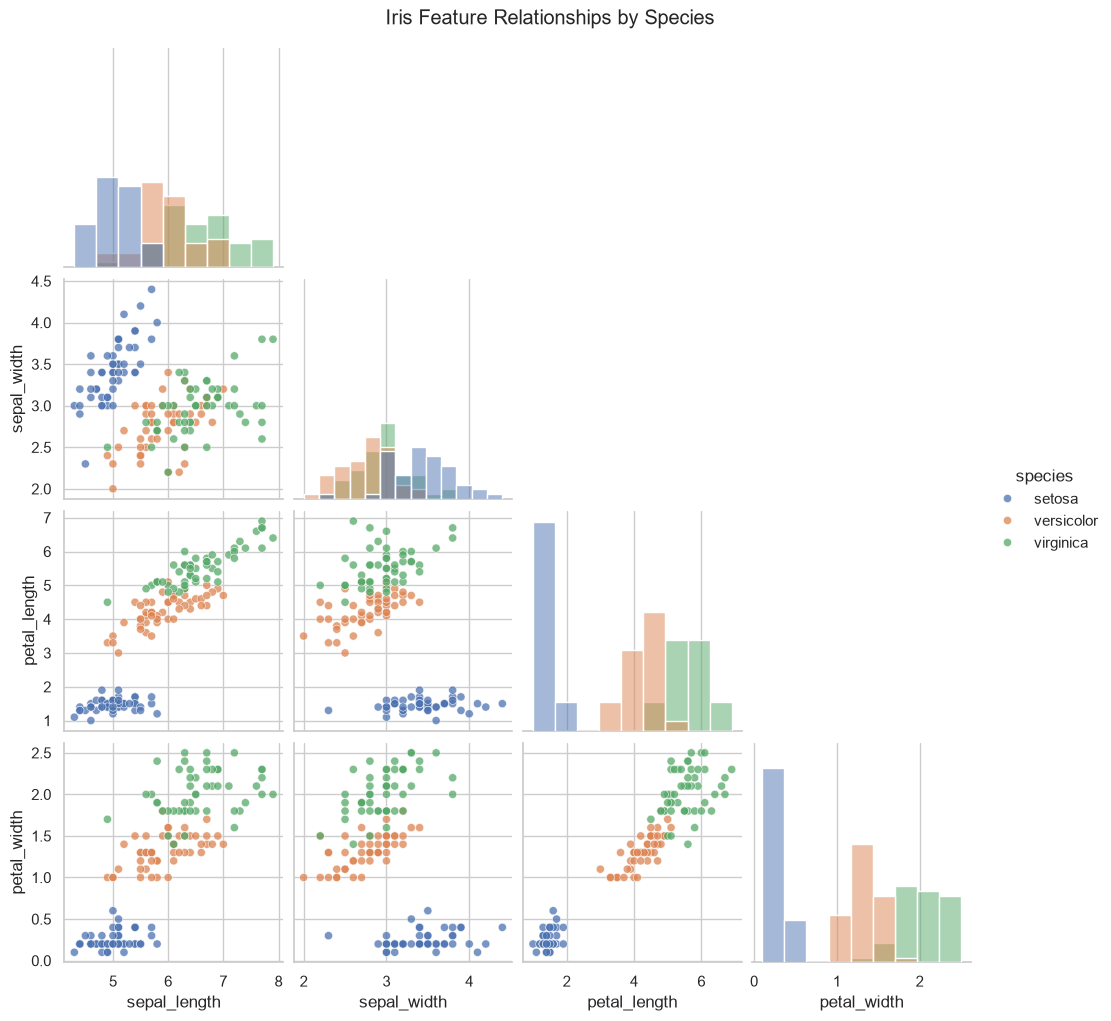

In [4]:
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
target_col = "species"

assert set(feature_cols + [target_col]).issubset(df.columns), "Expected columns are missing."
assert df[feature_cols].isna().sum().sum() == 0, "Numeric features contain missing values."
assert df[target_col].isna().sum() == 0, "Target contains missing values."

pair_grid = sns.pairplot(
    df,
    vars=feature_cols,
    hue=target_col,
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.75, "s": 35}
)
pair_grid.fig.suptitle("Iris Feature Relationships by Species", y=1.02)
plt.show()


## 5. Prepare features and perform an 80/20 split

The target labels are `species`; the four measurements are input features. A stratified split preserves the class proportions in both subsets. Scaling is performed inside a scikit-learn `Pipeline`, so the scaler is fitted only on the training data and does not learn from the test set.


In [5]:
X = df[feature_cols].copy()
y = df[target_col].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training samples: {len(X_train)} ({len(X_train) / len(df):.0%})")
print(f"Test samples:     {len(X_test)} ({len(X_test) / len(df):.0%})")
print("\\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Test class proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion").to_frame())


Training samples: 120 (80%)
Test samples:     30 (20%)
\nTraining class proportions:


,proportion
species,
setosa,0.333333
versicolor,0.333333
virginica,0.333333


Test class proportions:


,proportion
species,
setosa,0.333333
versicolor,0.333333
virginica,0.333333


## 6. Train the benchmark models

- **Logistic Regression:** a linear classification baseline. Standardization is important because it uses an optimization procedure sensitive to feature scales.
- **Decision Tree:** a non-linear, rule-based model. Scaling is not required by trees, but both models are kept in comparable pipelines to make the preprocessing workflow explicit.



In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ])
}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{model_name}: training complete")


Logistic Regression: training complete
Decision Tree: training complete


## 7. Evaluate and benchmark performance

Precision, recall, and F1-score use **macro averaging**, which calculates each class's metric independently and then averages them equally. This is appropriate for a multi-class comparison and remains interpretable if class sizes differ.


In [7]:
results = []
predictions = {}

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values("F1-score (macro)", ascending=False)
display(results_df.style.format("{:.3f}").highlight_max(axis=0, props="font-weight: bold;"))

best_model_name = results_df["F1-score (macro)"].idxmax()
print(f"Best model by macro F1-score on this test split: {best_model_name}")


,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


Best model by macro F1-score on this test split: Logistic Regression


## 8. Classification reports


In [8]:
for model_name, y_pred in predictions.items():
    print("=" * 72)
    print(model_name)
    print(classification_report(y_test, y_pred, digits=3, zero_division=0))


Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30



## 9. Confusion matrix heatmaps


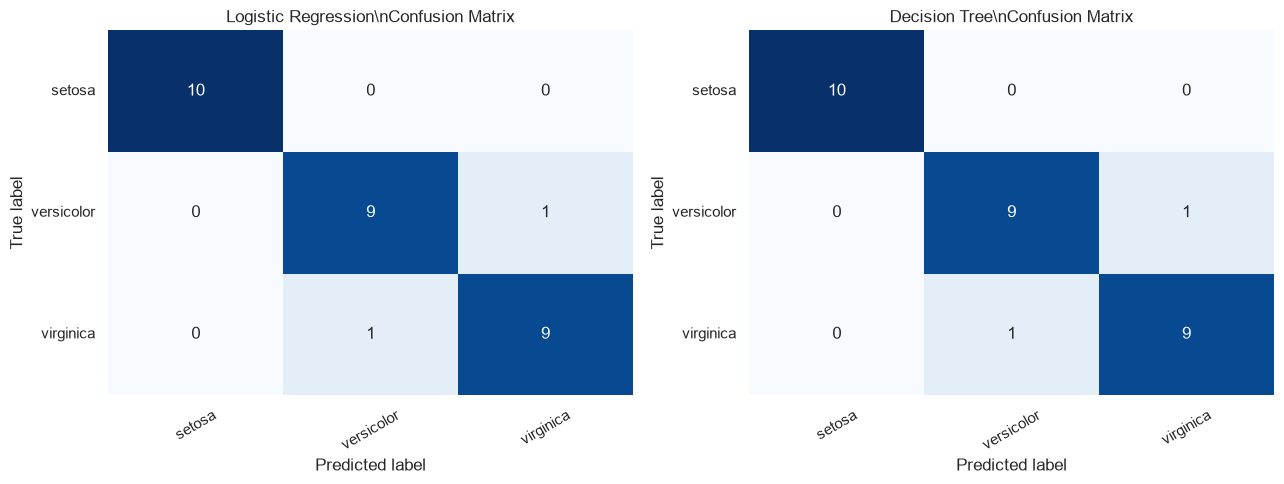

In [9]:
class_labels = sorted(y.unique())

fig, axes = plt.subplots(1, len(models), figsize=(13, 5))
for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=class_labels, yticklabels=class_labels, ax=ax
    )
    ax.set_title(f"{model_name}\\nConfusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


## 10. Compare metrics visually



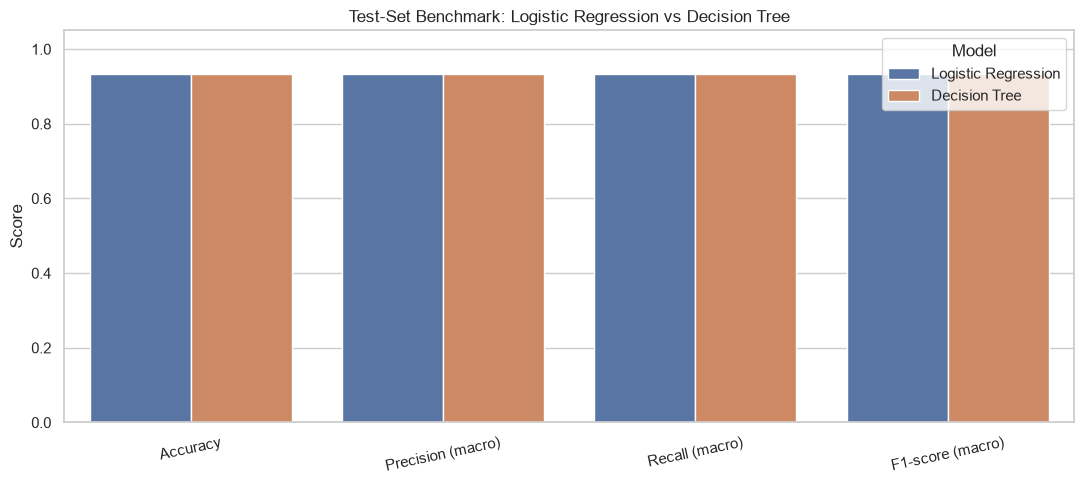

In [10]:
metrics_to_plot = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
results_long = (
    results_df.reset_index()
    .melt(id_vars="Model", value_vars=metrics_to_plot,
          var_name="Metric", value_name="Score")
)

plt.figure(figsize=(11, 5))
sns.barplot(data=results_long, x="Metric", y="Score", hue="Model")
plt.ylim(0, 1.05)
plt.title("Test-Set Benchmark: Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.xlabel("")
plt.xticks(rotation=12)
plt.legend(title="Model")
plt.tight_layout()
plt.show()


## 11. Decision-boundary visualization (two features)

A decision boundary is two-dimensional, so this plot deliberately trains separate models using only `petal_length` and `petal_width`. It is a visualization of how each algorithm partitions this feature plane; it is **not** the same model as the four-feature benchmark above.

The plot uses the same train/test split indices and keeps preprocessing inside the pipeline.


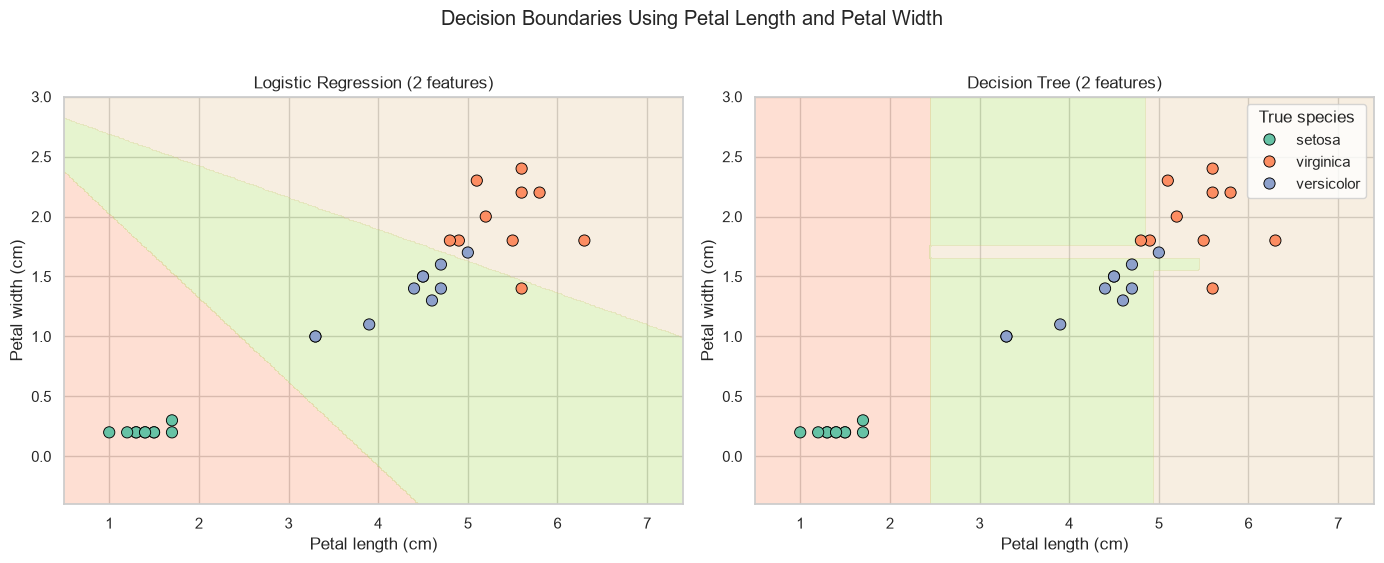

In [11]:
boundary_features = ["petal_length", "petal_width"]
Xb = df[boundary_features]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

boundary_models = {
    "Logistic Regression (2 features)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree (2 features)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ])
}

for model in boundary_models.values():
    model.fit(Xb_train, yb_train)

x_min, x_max = Xb[boundary_features[0]].min() - 0.5, Xb[boundary_features[0]].max() + 0.5
y_min, y_max = Xb[boundary_features[1]].min() - 0.5, Xb[boundary_features[1]].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)
grid = pd.DataFrame({
    boundary_features[0]: xx.ravel(),
    boundary_features[1]: yy.ravel()
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
palette = sns.color_palette("Set2", n_colors=len(class_labels))
for ax, (name, model) in zip(axes, boundary_models.items()):
    grid_pred = model.predict(grid)
    class_to_int = {label: i for i, label in enumerate(class_labels)}
    zz = np.array([class_to_int[label] for label in grid_pred]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.28, levels=np.arange(-0.5, len(class_labels) + 0.5, 1),
                cmap="Set2")
    sns.scatterplot(
        data=pd.DataFrame({boundary_features[0]: Xb_test[boundary_features[0]].values,
                           boundary_features[1]: Xb_test[boundary_features[1]].values,
                           "species": yb_test.values}),
        x=boundary_features[0], y=boundary_features[1], hue="species",
        palette=palette, s=65, edgecolor="black", ax=ax, legend=(ax is axes[1])
    )
    ax.set_title(name)
    ax.set_xlabel("Petal length (cm)")
    ax.set_ylabel("Petal width (cm)")

axes[1].legend(title="True species", loc="best")
plt.suptitle("Decision Boundaries Using Petal Length and Petal Width", y=1.02)
plt.tight_layout()
plt.show()


## 12. Final interpretation

Use the actual metrics printed above to write a short, evidence-based conclusion. Do not hard-code performance claims: results can change if the split, random seed, or library versions change.

Suggested points to address:
1. Which model scored highest on the held-out test set?
2. Which species, if any, were misclassified in the confusion matrix?
3. How do the macro precision, recall, and F1-score compare?
4. Why is the two-feature decision-boundary experiment different from the four-feature benchmark?
5. Why is fitting the scaler only on training data important?


In [12]:
print("FINAL TEST-SET SUMMARY")
display(results_df.style.format("{:.3f}"))
print(f"Selected by macro F1-score: {best_model_name}")
print("Use the confusion matrices and classification reports above to support your written conclusion.")


FINAL TEST-SET SUMMARY


,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


Selected by macro F1-score: Logistic Regression
Use the confusion matrices and classification reports above to support your written conclusion.


## 13. Optional: save the benchmark table

This writes the metrics table to `outputs/benchmark_metrics.csv`. The folder is created automatically.


In [13]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
results_df.to_csv(output_dir / "benchmark_metrics.csv")
print(f"Saved: {output_dir / 'benchmark_metrics.csv'}")


Saved: outputs\benchmark_metrics.csv
